In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("Groq_API_KEY")

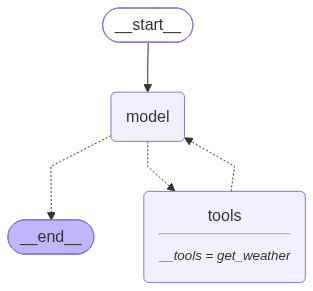

In [ ]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    reasoning_effort="low",
    model_kwargs={
        "include_reasoning": False
    }
)

def get_weather(city:str)-> str:
    """Get Weather of a City"""
    return f"The weather in {city} is Sunny."

agent = create_agent(
    model = llm,
    tools= [get_weather],
    system_prompt = "You are a helpful assistant."
)
agent

In [32]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is the weather in Delhi?"
        }
    ]
})

In [33]:
print(response["messages"][-2].content)

The weather in Delhi is Sunny.


## Streaming

Models like ChatGPT, Gemeni and many other models make use of Stream while generated it's output. Basically they then produce the output while the new content is generated at the same time.
We can simply do this by using/calling 'stream()' instead of 'invoke()' and use 'stream_mode = "messages" '

'stream()' func' returns an iterator consisting output in chunks.

In [51]:
words = 0
for chunk, metadata in agent.stream(
    {
        "messages": [
            {"role": "user", "content": "List several Advantages and Disadvantages of Agentic AI"}
        ]
    },
    stream_mode="messages"
):
    print(chunk.content, end="", flush=True)
    words += 1
    if(words > 16):
        print("\n")
        words = 0

**Agentic AI** refers to artificial intelligence systems that possess a degree of autonomy

, self‑direction, and goal‑oriented behavior—often modeled after human-like

 agency. Below are some key advantages and disadvantages of deploying such systems.

---

## Advantages



| # | Advantage | Why it matters |
|---|-----------|----------------|


| 1 | **Scalability of Decision‑Making** | Agentic AI

 can process vast amounts of data and make decisions in real time, far beyond human capacity

. |
| 2 | **Consistency & Reliability** | Once trained, agents apply

 the same rules and logic, reducing human error and bias that arise from fatigue or incons

istency. |
| 3 | **Rapid Adaptation** | Many agentic systems

 incorporate reinforcement learning or online learning, allowing them to adjust to new environments or objectives quickly

. |
| 4 | **Cost Efficiency** | Automating routine or complex tasks

 can lower labor costs and free human workers for higher‑value activities. |
| 

5 | **

## Batching

Batching helps to improve performance and reduce model cost, by doing processing in parallel.

In [58]:
responses = agent.batch([{"messages":'What is the weather in Delhi ?'},
             {"messages": 'Explain about AI bubble in short'},
             {"messages": 'Are we going to see any big financial crisis because of AI ? Discuss in short'}],
             
             config={"max_concurrency": 4}) ## This means maximum 4 request can be processed parallely.

In [66]:
i = 0
for response in responses:
    print(f"Answer of {i+1} Question:-")
    print(response["messages"][-1].content)
    print("\n")
    i += 1 

Answer of 1 Question:-
The weather in Delhi is sunny.


Answer of 2 Question:-
The “AI bubble” refers to the rapid surge in hype, investment, and expectations around artificial intelligence—especially generative models—over the past few years. It’s characterized by:

1. **Excessive optimism** – Many claim AI will solve almost any problem, from healthcare to climate change, often overlooking limitations.
2. **Massive capital inflows** – Startups and established firms receive huge funding, sometimes without proven products or clear monetization paths.
3. **Media amplification** – Headlines tout “AI breakthroughs” that may be incremental or context‑specific, inflating public perception.
4. **Talent and resource crunch** – A rush to hire AI talent and acquire data can drive up costs and create bottlenecks.
5. **Risk of over‑promising** – When expectations don’t match reality, projects stall, investors lose confidence, and the market can correct sharply.

In short, the AI bubble is the peri